Odnajdujemy projekt i umożliwiamy import wspólnych modułów.

In [1]:
from pathlib import Path
import sys

project_root = next(
    (
        path
        for path in (Path.cwd(), *Path.cwd().parents)
        if (path / "src/restore_pipeline/super_resolution").is_dir()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError("Uruchom notebook wewnątrz katalogu projektu.")

source_path = str(project_root / "src")

if source_path not in sys.path:
    sys.path.insert(0, source_path)


Importujemy wyłącznie obsługę treningu, checkpointów i wykresów jego przebiegu.

In [2]:
import matplotlib.pyplot as plt
import torch
from restore_pipeline.super_resolution.training import train_models, resume_models
from restore_pipeline.super_resolution.checkpoints import read_checkpoint
from restore_pipeline.super_resolution.visualization import (
    set_plot_style,
    plot_history,
    plot_learning_rate,
)

from restore_pipeline.super_resolution.paths import display_path


Ustawiamy wspólny trening oraz listę modeli, a do wznowienia wybieramy resume i uzupełniamy RESUME_PATHS.

In [3]:
RUN_MODE = "train"
EPOCHS = 50
SHOW_PROGRESS = True
NUM_WORKERS = 0

DATASET_PATH = project_root / "notebooks/igoh/data/partitioned_dataset"
EXPERIMENTS_PATH = project_root / "notebooks/igoh/models_weights/experiments"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAINING = {
    "num_workers": NUM_WORKERS,
    "scale_factor": 2,
    "hr_size": 256,
    "batch_size": 64,
    "learning_rate": 0.001,
    "train_limit": 12800,
    "val_limit": 2560,
    "seed": 42,
    "augment_train": True,
    "lr_step_size": 10,
    "lr_gamma": 0.5,
}

MODELS = [
    {
        "name": "ESPCN3",
        "architecture": "espcn3_v1",
        "params": {},
    },
    {
        "name": "EDSR4",
        "architecture": "edsr_small_v1",
        "params": {"hidden_channels": 16, "num_blocks": 4},
    },
]

RESUME_PATHS = []


Trenujemy modele kolejno albo wznawiamy wybrane katalogi do łącznego celu EPOCHS, zachowując MSE i zapisaną konfigurację.

In [4]:
if RUN_MODE == "train":
    run_paths = train_models(
        MODELS,
        TRAINING,
        DATASET_PATH,
        EXPERIMENTS_PATH,
        epochs=EPOCHS,
        device=DEVICE,
        show_progress=SHOW_PROGRESS,
    )
elif RUN_MODE == "resume":
    run_paths = resume_models(
        RESUME_PATHS,
        DATASET_PATH,
        epochs=EPOCHS,
        device=DEVICE,
        show_progress=SHOW_PROGRESS,
    )
else:
    raise ValueError("Wybierz RUN_MODE='train' albo 'resume'.")


Model 1/2: ESPCN3
Eksperyment: notebooks/igoh/models_weights/experiments/ESPCN3_x2_mse_20261109_185704_405012
Uczenie: 12800; walidacja robocza: 2560


Trening:   0%|          | 0/200 [00:00<?, ?partia/s]

Walidacja:   0%|          | 0/40 [00:00<?, ?partia/s]

Epoka 1/50 · MSE: train=0.013795, val=0.003614, lr=1.0e-03 | 31.7 s


Trening:   0%|          | 0/200 [00:00<?, ?partia/s]

Walidacja:   0%|          | 0/40 [00:00<?, ?partia/s]

... (291 outputs left out)

Epoka 49/50 · MSE: train=0.001268, val=0.001281, lr=6.3e-05 | 65.6 s


Trening:   0%|          | 0/200 [00:00<?, ?partia/s]

Walidacja:   0%|          | 0/40 [00:00<?, ?partia/s]

Epoka 50/50 · MSE: train=0.001266, val=0.001279, lr=6.3e-05 | 65.0 s


Pokazujemy i zapisujemy pełne krzywe treningu oraz learning rate bez uruchamiania benchmarku.

notebooks/igoh/models_weights/experiments/ESPCN3_x2_mse_20261109_185704_405012


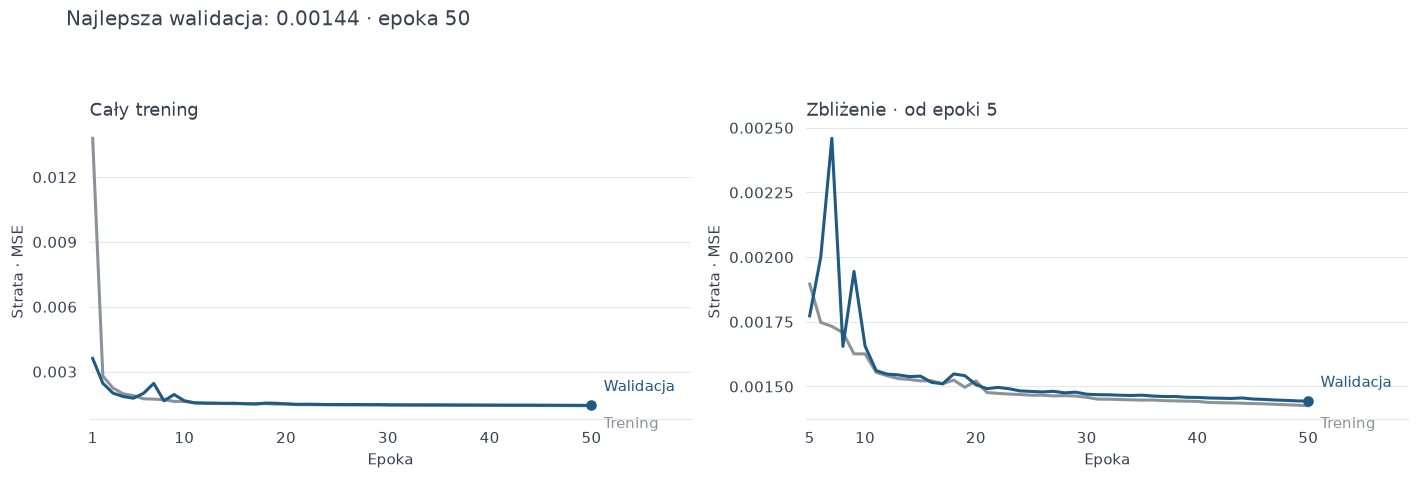

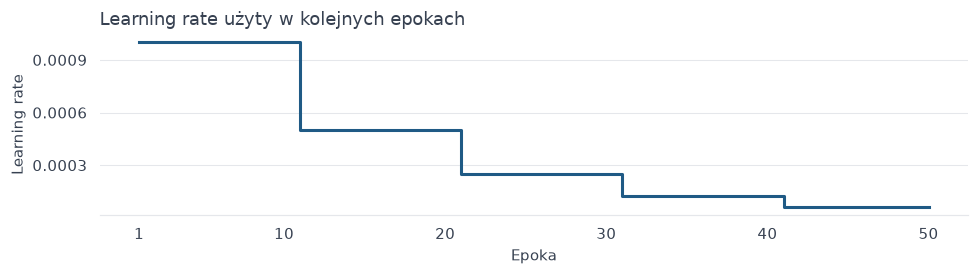

notebooks/igoh/models_weights/experiments/EDSR4_x2_mse_20261109_192402_212926


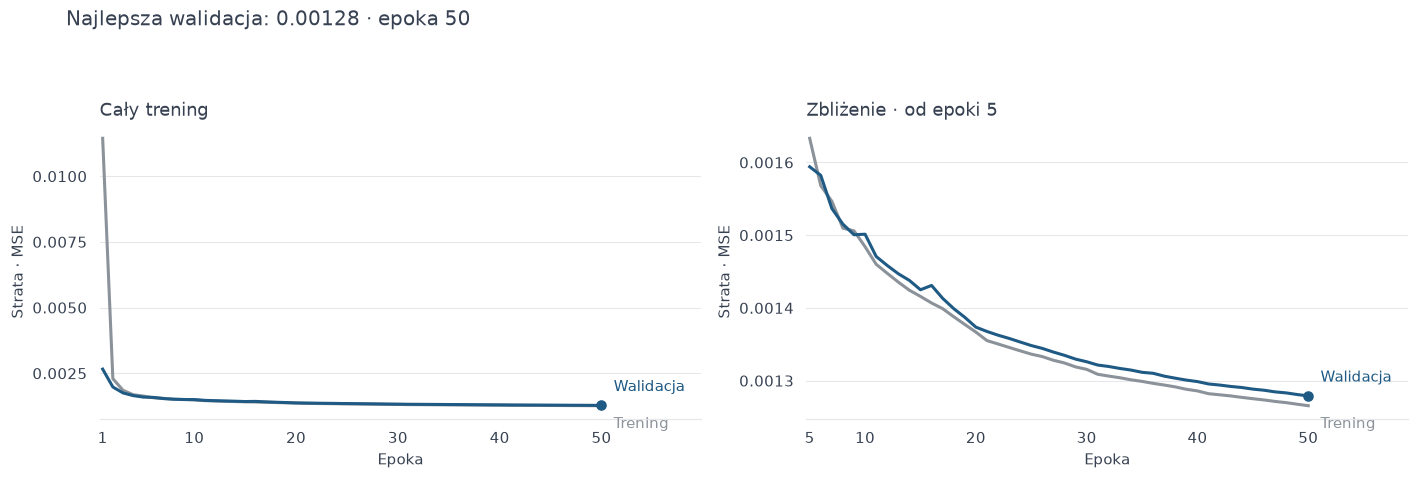

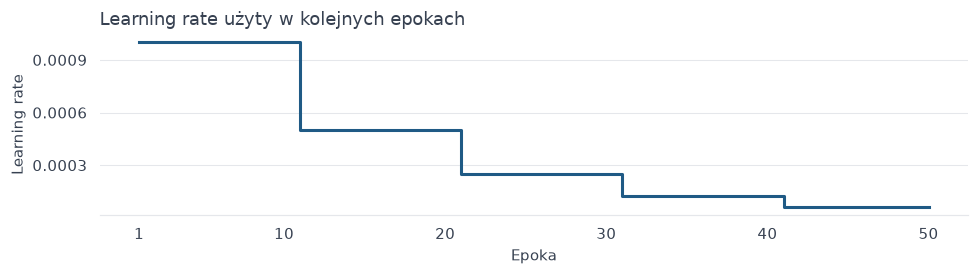

In [5]:
set_plot_style()

for run_path in run_paths:
    checkpoint = read_checkpoint(run_path / "last.pt")
    print(display_path(run_path))

    for filename, figure in (
        ("training_loss.png", plot_history(checkpoint["history"])),
        ("learning_rate.png", plot_learning_rate(checkpoint["history"])),
    ):
        figure.savefig(run_path / filename, dpi=150, bbox_inches="tight")
        display(figure)
        plt.close(figure)
